<font size = 6>Import libraries</font>

In [6]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from mlxtend.plotting import plot_confusion_matrix 
from sklearn.metrics import confusion_matrix , classification_report


<font size = 6>Loading dataset</font>

In [7]:

train_path = "dataset/train"
valid_path = "dataset/valid"
test_path = "dataset/test"

train_batches = tf.keras.utils.image_dataset_from_directory(
    train_path,
    batch_size = 1,
    shuffle=False,
    image_size = (224,224),
    label_mode = "categorical"
)

valid_batches = tf.keras.utils.image_dataset_from_directory(
    valid_path,
    batch_size = 1,
    shuffle=False,
    image_size = (224,224),
    label_mode = "categorical"
)

test_batches = tf.keras.utils.image_dataset_from_directory(
    test_path,
    batch_size = 1,
    shuffle=False,
    image_size = (224,224),
    label_mode = "categorical"
)

print(train_batches.class_names)

Found 700 files belonging to 2 classes.


Found 200 files belonging to 2 classes.
Found 100 files belonging to 2 classes.
['cat', 'dog']


<font size=6>Plot example of dataset</font>

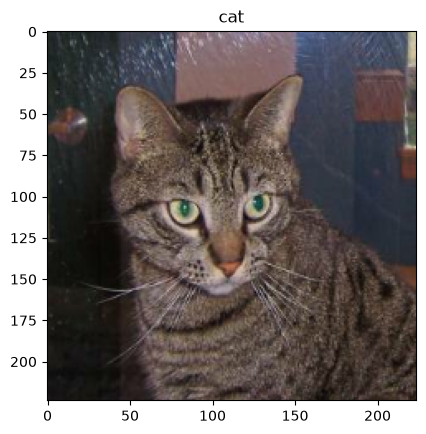

In [8]:

for image, label in train_batches.take(1):
    image = image[0].numpy().astype("uint8")
    label  = label[0].numpy().argmax()

    plt.imshow(image)
    plt.title(train_batches.class_names[label])


<font size=6>Load the pretrained model (EfficientNetB0  with ~4 Milion Parameters)</font>

<font size=5>Freeze the input layers and add our fully conected layer</font>

In [9]:

pre_model = tf.keras.applications.EfficientNetB0(include_top=False , input_shape=(224,224,3) , weights="imagenet")

for layer in pre_model.layers:
    layer.trainable = False

tf.keras.utils.clear_session()
tf.random.set_seed(42)

last_layer = pre_model.get_layer("top_activation")
last_output = last_layer.output

x = tf.keras.layers.GlobalAveragePooling2D()(last_output)
x = tf.keras.layers.Dense(64 , activation="relu", name="FC_2")(x)
x = tf.keras.layers.Dropout(rate=0.5)(x)
x = tf.keras.layers.Dense(2 , activation="softmax" , name="softmax")(x)

new_model = tf.keras.Model(inputs=pre_model.input,outputs=x)

In [10]:
new_model.summary(show_trainable=True)  # The all layers are freezed

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer       │ (None, 224,     │         0 │ -              │   -   │
│ (InputLayer)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ rescaling         │ (None, 224,     │         0 │ input_layer[0… │   -   │
│ (Rescaling)       │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ normalization     │ (None, 224,     │         7 │ rescaling[0][… │   N   │
│ (Normalization)   │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ rescaling_1       │ (None, 224,     │         0 │ normalization… │   -   │
│ (Rescaling)       │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ stem_conv_pad     │ (None, 225,     │         0 │ rescaling_1[0… │   -   │
│ (ZeroPadding2D)   │ 225, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ stem_conv         │ (None, 112,     │       864 │ stem_conv_pad… │   N   │
│ (Conv2D)          │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ stem_bn           │ (None, 112,     │       128 │ stem_conv[0][… │   N   │
│ (BatchNormalizat… │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ stem_activation   │ (None, 112,     │         0 │ stem_bn[0][0]  │   -   │
│ (Activation)      │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_dwconv    │ (None, 112,     │       288 │ stem_activati… │   N   │
│ (DepthwiseConv2D) │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_bn        │ (None, 112,     │       128 │ block1a_dwcon… │   N   │
│ (BatchNormalizat… │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_activati… │ (None, 112,     │         0 │ block1a_bn[0]… │   -   │
│ (Activation)      │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_se_squee… │ (None, 32)      │         0 │ block1a_activ… │   -   │
│ (GlobalAveragePo… │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_se_resha… │ (None, 1, 1,    │         0 │ block1a_se_sq… │   -   │
│ (Reshape)         │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_se_reduce │ (None, 1, 1, 8) │       264 │ block1a_se_re… │   N   │
│ (Conv2D)          │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_se_expand │ (None, 1, 1,    │       288 │ block1a_se_re… │   N   │
│ (Conv2D)          │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_se_excite │ (None, 112,     │         0 │ block1a_activ… │   -   │
│ (Multiply)        │ 112, 32)        │           │ block1a_se_ex… │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block1a_project_… │ (None, 112,     │       512 │ block1a_se_ex… │   N 

 Total params: 4,131,685 (15.76 MB)

 Trainable params: 82,114 (320.76 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

<font size=6>Compile and training the model</font>

In [11]:
new_model.compile(loss=tf.keras.losses.categorical_crossentropy , metrics=["accuracy"] , optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001))

history = new_model.fit(train_batches , epochs=7 , validation_data=valid_batches)

Epoch 1/7


/home/erfanjenab/Code/main/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794802469.378699    7808 service.cc:153] XLA service 0x7ed5f0067e50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794802469.378724    7808 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1794802469.567054    7808 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794802470.843040    7808 cuda_dnn.cc:461] Loaded cuDNN version 92700


 24/700 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7917 - loss: 0.4870     

I0000 00:00:1794802483.179737    7808 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


700/700 ━━━━━━━━━━━━━━━━━━━━ 31s 18ms/step - accuracy: 0.9357 - loss: 0.1750 - val_accuracy: 0.9200 - val_loss: 0.2259
Epoch 2/7
700/700 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9843 - loss: 0.0652 - val_accuracy: 0.9800 - val_loss: 0.0656
Epoch 3/7
700/700 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9886 - loss: 0.0472 - val_accuracy: 0.9850 - val_loss: 0.0359
Epoch 4/7
700/700 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9986 - loss: 0.0190 - val_accuracy: 0.9950 - val_loss: 0.0251
Epoch 5/7
700/700 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9943 - loss: 0.0197 - val_accuracy: 0.9950 - val_loss: 0.0215
Epoch 6/7
700/700 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9957 - loss: 0.0152 - val_accuracy: 0.9950 - val_loss: 0.0161
Epoch 7/7
700/700 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9971 - loss: 0.0105 - val_accuracy: 1.0000 - val_loss: 0.0117


<font size=6>Evaluate model on test data</font>

In [12]:
new_model.evaluate(test_batches)

100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 1.0000 - loss: 0.0021


[0.0021448314655572176, 1.0]

<font size = 6>Plot learning curve</font>

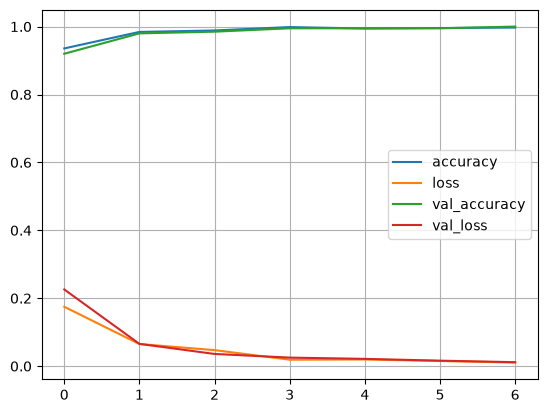

In [ ]:
plt.plot(pd.DataFrame(history.history) , label = history.history.keys())
plt.legend()
plt.grid()
# plt.savefig("learning_curve.png")

<font size=6>Plot confusion matrix</font>

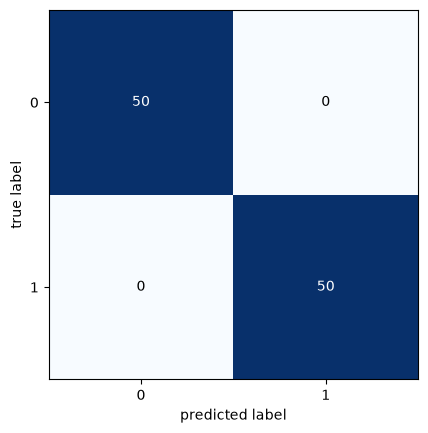

In [ ]:
y_true = []
y_pred = []

for images, labels in test_batches:
    predictions = new_model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

cm = confusion_matrix(y_true , y_pred)

plot_confusion_matrix(cm)
# plt.savefig("confusion_matrix.png")

<font size=6>Print the important metric of model on test dataset</font>

In [19]:
print(classification_report(y_true , y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       1.00      1.00      1.00        50

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



<font size=6>Evaluate model on new image (Cats)</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
The predict of model is Cat
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The Coefficient of predict is [[1. 0.]]


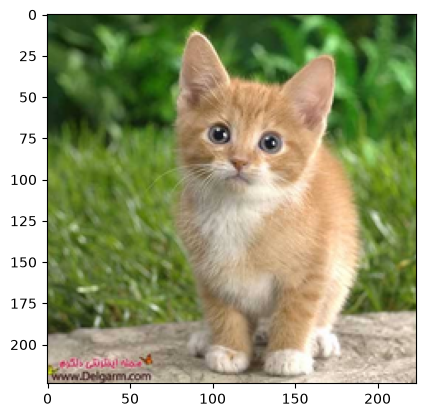

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The predict of model is Cat
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
The Coefficient of predict is [[1. 0.]]


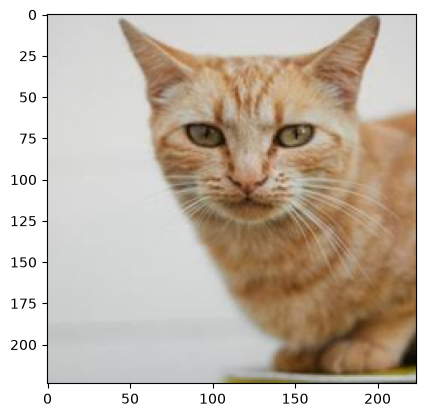

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
The predict of model is Cat
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The Coefficient of predict is [[1. 0.]]


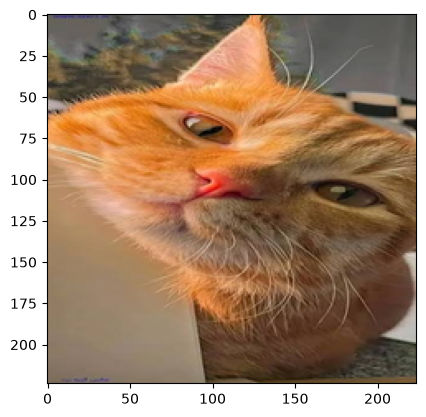

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The predict of model is Cat
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The Coefficient of predict is [[1. 0.]]


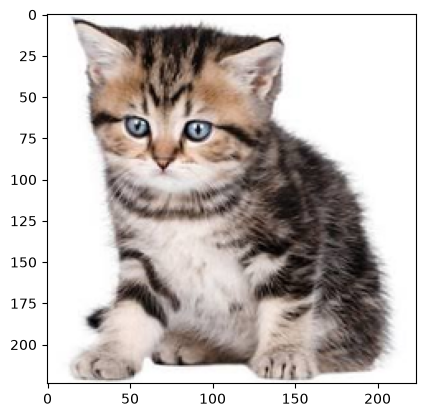

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
The predict of model is Cat
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
The Coefficient of predict is [[1. 0.]]


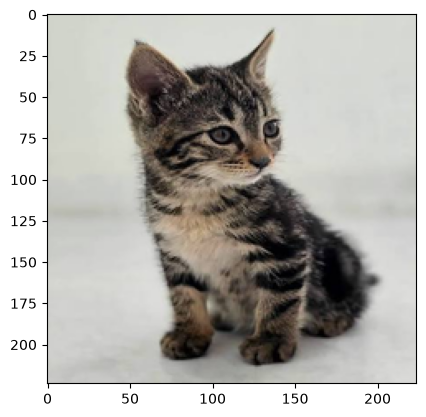

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The predict of model is Cat
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The Coefficient of predict is [[1. 0.]]


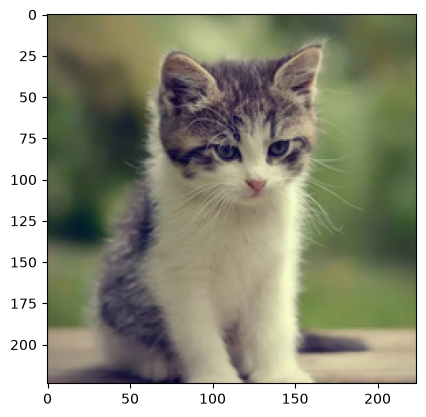

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
The predict of model is Cat
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
The Coefficient of predict is [[1. 0.]]


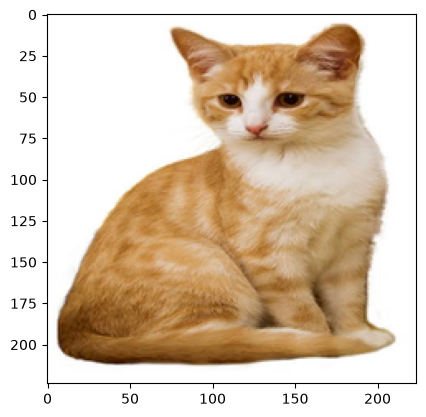

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The predict of model is Cat
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
The Coefficient of predict is [[1. 0.]]


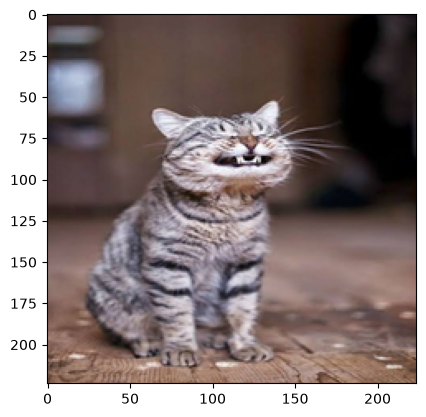

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
The predict of model is Cat
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
The Coefficient of predict is [[1. 0.]]


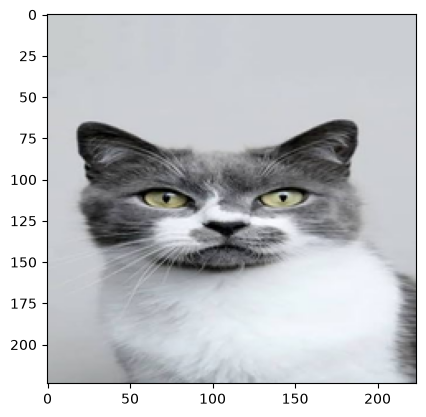

In [16]:

for i in np.arange(1,10,1):
    img = Image.open(f"new_pictures/cat{i}.jpg")
    img = img.convert("RGB")
    img = img.resize((224,224) , resample=Image.Resampling.LANCZOS)
    img = np.array(img).reshape(-1,224,224,3)

    y_predict = new_model.predict(img).argmax()

    if y_predict == 0:
        print("The predict of model is Cat")
        print(f'The Coefficient of predict is {new_model.predict(img).round(3)}')
    else:
        print("The predict of model is Dog")
        print(f'The Coefficient of predict is {new_model.predict(img).round(3)}')
        
    plt.imshow(img[0])
    plt.show()


<font size=6>Evaluate model on new image (Dogs)</font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The predict of model is Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The Coefficient of predict is [[0.034 0.966]]


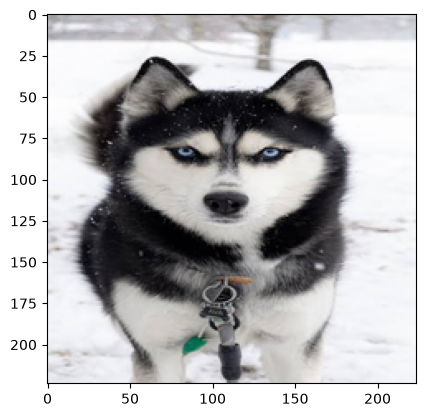

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
The predict of model is Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
The Coefficient of predict is [[0.442 0.558]]


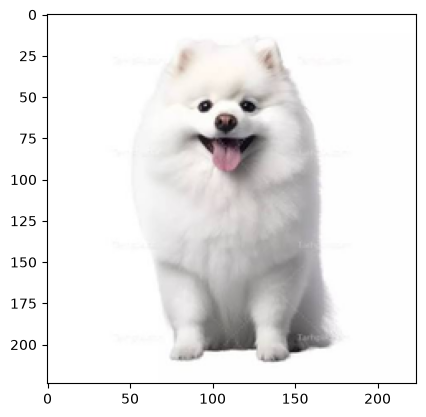

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
The predict of model is Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The Coefficient of predict is [[0.006 0.994]]


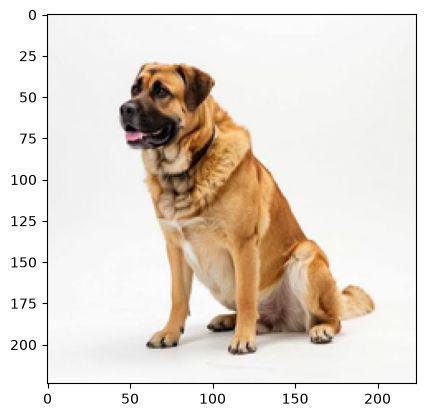

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
The predict of model is Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
The Coefficient of predict is [[0. 1.]]


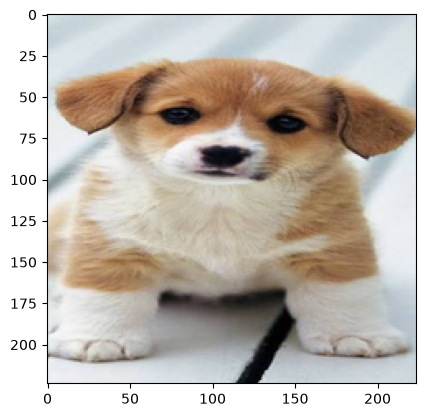

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The predict of model is Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
The Coefficient of predict is [[0.017 0.983]]


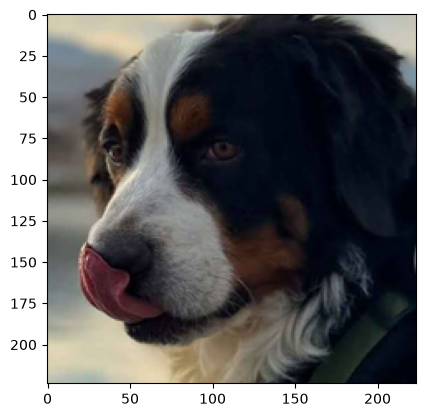

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
The predict of model is Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The Coefficient of predict is [[0.001 0.999]]


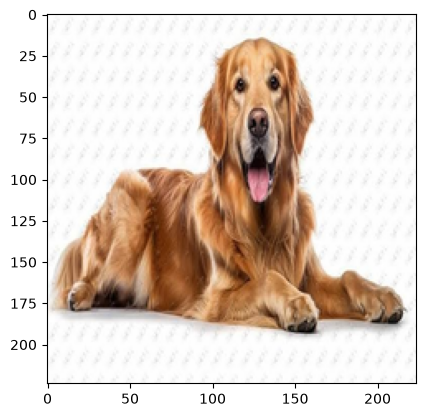

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The predict of model is Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
The Coefficient of predict is [[0.005 0.995]]


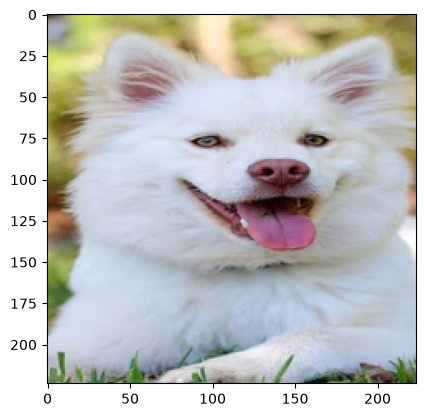

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
The predict of model is Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
The Coefficient of predict is [[0.004 0.996]]


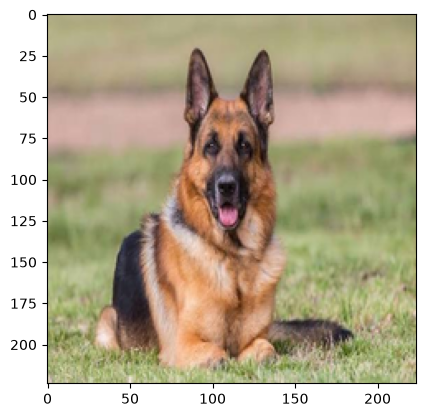

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
The predict of model is Dog
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
The Coefficient of predict is [[0.051 0.949]]


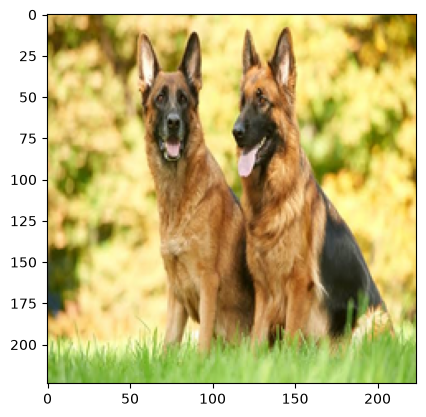

In [17]:

for i in np.arange(1,10,1):
    img = Image.open(f"new_pictures/dog{i}.jpg")
    img = img.convert("RGB")
    img = img.resize((224,224) , resample=Image.Resampling.LANCZOS)
    img = np.array(img).reshape(-1,224,224,3)

    y_predict = new_model.predict(img).argmax()

    if y_predict == 0:
        print("The predict of model is Cat")
        print(f'The Coefficient of predict is {new_model.predict(img).round(3)}')
    else:
        print("The predict of model is Dog")
        print(f'The Coefficient of predict is {new_model.predict(img).round(3)}')
        
    plt.imshow(img[0])
    plt.show()


<font size=6>Save the model</font>

In [18]:
# new_model.save("cat_dog_model_classifier.keras")

<font size=7>The End!</font>